# LAB02 - Logistic Regression và Softmax Regression với dataset FPT được thu thập trong LAB01

Dữ liệu: `LAB01/Bai02/FPT_stock.csv`

Tóm tắt bài làm:
- Bài 1: Logistic Regression bằng NumPy, phân loại phiên sau tăng / không tăng.
- Bài 2: Softmax Regression bằng NumPy, phân loại phiên sau giảm / đi ngang / tăng.
- Bài 3: Làm lại hai bài bằng Scikit-learn để so sánh.

Mỗi mẫu dùng thông tin đã biết khi kết thúc phiên hiện tại để dự đoán phiên kế tiếp.
Dùng giá đóng cửa điều chỉnh để tính lợi suất, giảm ảnh hưởng của chia tách/cổ tức.

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, accuracy_score

# Chạy được từ thư mục repo hoặc từ LAB02.
ROOT = Path(__file__).resolve().parent.parent if "__file__" in globals() else Path.cwd()
if not (ROOT / "LAB01").exists():
    ROOT = ROOT.parent

df = pd.read_csv(ROOT / "LAB01/Bai02/FPT_stock.csv", parse_dates=["date"])
df = df.sort_values("date").drop_duplicates("date").reset_index(drop=True)
print("Number of sessions:", len(df))
print(df.head().to_string(index=False))

Number of sessions: 1244
symbol       date  open  high  low  close  adjusted_close  volume  change_percent
   FPT 2021-10-11  99.0  99.3 98.3   99.2           49.82 2295500             0.3
   FPT 2021-10-12  99.2  99.2 98.5   99.0           49.72 1125300            -0.2
   FPT 2021-10-13  99.0 101.5 98.5   99.4           49.92 3232500             0.4
   FPT 2021-10-14  99.4 100.0 98.4   98.8           49.62 1824200            -0.6
   FPT 2021-10-15  99.4 100.1 98.4   98.9           49.67 1702500             0.1


## 1. Chuẩn bị dữ liệu

Dùng 5 đặc trưng đơn giản: lợi suất hôm nay, thay đổi giá trong phiên,
biên độ giá, thay đổi khối lượng và giá điều chỉnh so với trung bình 5 phiên

Nhãn dựa trên lợi suất phiên sau: `adjusted_close[t+1] / adjusted_close[t] - 1`.
- Phân loại nhị phân: chia thành 2 class 0 = không tăng (<= 0), 1 = tăng (> 0)
- Với bài tập 2, chia thành 3 lớp: 0 = giảm (< -1%), 1 = đi ngang (từ -1% đến 1%), 2 = tăng (> 1%).
Ngưỡng 1% được chọn cố định trước khi huấn luyện, không chọn dựa trên tập test.
Tạo lợi suất phiên sau trước khi bỏ dòng thiếu để luôn dự đoán phiên liền kế tiếp.

In [2]:
data = pd.DataFrame({"date": df["date"]})
data["return_today"] = df["adjusted_close"].pct_change(fill_method=None)
data["intraday_return"] = df["close"] / df["open"] - 1
data["price_range"] = (df["high"] - df["low"]) / df["open"]
data["volume_change"] = df["volume"].pct_change(fill_method=None)
data["ma5_ratio"] = df["adjusted_close"] / df["adjusted_close"].rolling(5).mean() - 1
data["next_return"] = df["adjusted_close"].shift(-1) / df["adjusted_close"] - 1
data = data.replace([np.inf, -np.inf], np.nan).dropna().reset_index(drop=True)

features = ["return_today", "intraday_return", "price_range", "volume_change", "ma5_ratio"]
X = data[features].to_numpy()
y_binary = (data["next_return"] > 0).astype(int).to_numpy()
y_multi = np.where(data["next_return"] < -0.01, 0,
                   np.where(data["next_return"] > 0.01, 2, 1))

# 80% phiên đầu để train, 20% phiên cuối để test. 
split = int(len(data) * 0.8)
X_train, X_test = X[:split], X[split:]
yb_train, yb_test = y_binary[:split], y_binary[split:]
ym_train, ym_test = y_multi[:split], y_multi[split:]

# Chỉ tính trung bình và độ lệch chuẩn trên tập train để tránh rò rỉ dữ liệu.
mean = X_train.mean(axis=0)
std = X_train.std(axis=0)
std[std == 0] = 1
X_train = (X_train - mean) / std
X_test = (X_test - mean) / std

# Thêm cột 1 để hệ số đầu tiên đóng vai trò bias trong mô hình NumPy.
X_train_bias = np.column_stack([np.ones(len(X_train)), X_train])
X_test_bias = np.column_stack([np.ones(len(X_test)), X_test])

print("Train:", len(X_train), "| Test:", len(X_test))
print("Training feature dates:", data["date"].iloc[0].date(), "to", data["date"].iloc[split - 1].date())
print("Test feature dates:", data["date"].iloc[split].date(), "to", data["date"].iloc[-1].date())
print("Class counts (train/test):")
print("Binary:", np.bincount(yb_train, minlength=2), np.bincount(yb_test, minlength=2))
print("Three classes:", np.bincount(ym_train, minlength=3), np.bincount(ym_test, minlength=3))

Train: 991 | Test: 248
Training feature dates: 2021-10-15 to 2025-10-07
Test feature dates: 2025-10-08 to 2026-10-08
Class counts (train/test):
Binary: [507 484] [145 103]
Three classes: [205 565 221] [ 82 107  59]


## Bài 1. Logistic Regression bằng NumPy

Xác suất tăng: `p = sigmoid(X @ w)`.
Loss là binary cross-entropy; gradient là `X.T @ (p - y) / n`.
Cập nhật bằng Gradient Descent: `w = w - learning_rate * gradient`.
NumPy thực hiện toàn bộ mô hình và huấn luyện; Scikit-learn chỉ in các chỉ số đánh giá.

              precision    recall  f1-score   support

Non-Increase     0.6316    0.5793    0.6043       145
    Increase     0.4696    0.5243    0.4954       103

    accuracy                         0.5565       248
   macro avg     0.5506    0.5518    0.5499       248
weighted avg     0.5643    0.5565    0.5591       248



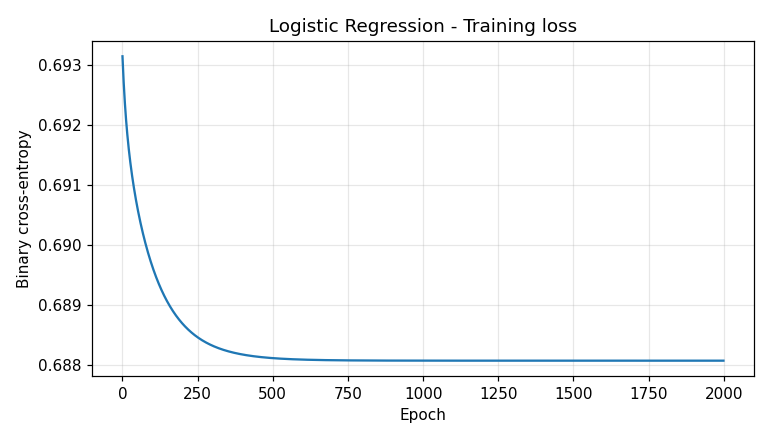

In [3]:
def sigmoid(z):
    return 1 / (1 + np.exp(-np.clip(z, -500, 500)))


def train_logistic(X, y, learning_rate=0.1, epochs=2000):
    w = np.zeros(X.shape[1])
    losses = []
    for epoch in range(epochs):
        z = X @ w
        p = sigmoid(z)
        # logaddexp tính binary cross-entropy ổn định, tránh log(0).
        loss = np.mean(np.logaddexp(0, z) - y * z)
        losses.append(loss)
        gradient = X.T @ (p - y) / len(y)
        w -= learning_rate * gradient
    return w, losses


w, logistic_losses = train_logistic(X_train_bias, yb_train)
pred_binary = (sigmoid(X_test_bias @ w) >= 0.5).astype(int)
print(classification_report(yb_test, pred_binary, labels=[0, 1],
                            target_names=["Non-Increase", "Increase"], digits=4, zero_division=0))

plt.figure(figsize=(7, 4))
plt.plot(logistic_losses)
plt.title("Logistic Regression - Training loss")
plt.xlabel("Epoch")
plt.ylabel("Binary cross-entropy")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

## Bài 2. Softmax Regression bằng NumPy

Softmax biến 3 điểm số thành 3 xác suất có tổng bằng 1.
Trừ điểm lớn nhất trước khi lấy exp để tránh tràn số.
Dùng nhãn one-hot và gradient `X.T @ (P - Y) / n`.

              precision    recall  f1-score   support

    Decrease     0.0000    0.0000    0.0000        82
    Sideways     0.4398    0.9907    0.6092       107
    Increase     0.6000    0.0508    0.0938        59

    accuracy                         0.4395       248
   macro avg     0.3466    0.3472    0.2343       248
weighted avg     0.3325    0.4395    0.2851       248



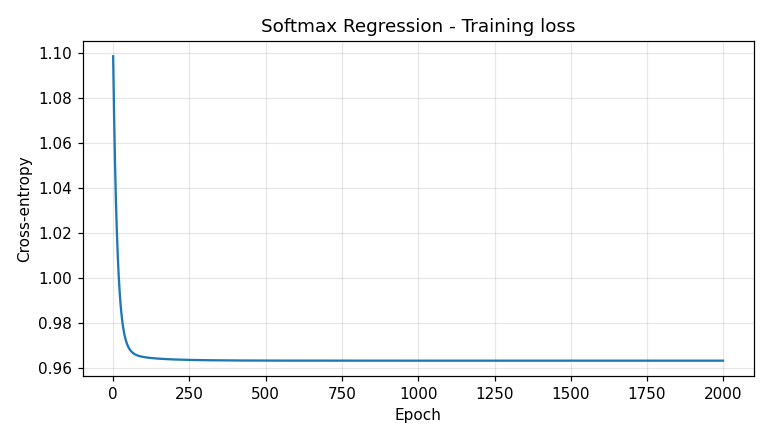

In [4]:
def softmax(z):
    z = z - z.max(axis=1, keepdims=True)
    exp_z = np.exp(z)
    return exp_z / exp_z.sum(axis=1, keepdims=True)


def train_softmax(X, y, learning_rate=0.1, epochs=2000):
    W = np.zeros((X.shape[1], 3))
    Y = np.eye(3)[y]
    losses = []
    for epoch in range(epochs):
        P = softmax(X @ W)
        loss = -np.mean(np.log(np.clip(P[np.arange(len(y)), y], 1e-15, 1)))
        losses.append(loss)
        gradient = X.T @ (P - Y) / len(y)
        W -= learning_rate * gradient
    return W, losses


W, softmax_losses = train_softmax(X_train_bias, ym_train)
pred_multi = softmax(X_test_bias @ W).argmax(axis=1)
print(classification_report(ym_test, pred_multi, labels=[0, 1, 2],
                            target_names=["Decrease", "Sideways", "Increase"], digits=4, zero_division=0))

plt.figure(figsize=(7, 4))
plt.plot(softmax_losses)
plt.title("Softmax Regression - Training loss")
plt.xlabel("Epoch")
plt.ylabel("Cross-entropy")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

## Bài 3. Logistic và Softmax Regression bằng Scikit-learn

Scikit-learn tự thêm bias nên dùng X chưa thêm cột 1.
Với 3 lớp, solver lbfgs tối ưu multinomial loss (Softmax Regression).
Đặt C lớn để giảm regularization, giúp so sánh với mô hình NumPy không regularization.

In [5]:
logistic_sklearn = LogisticRegression(solver="lbfgs", C=1e6, max_iter=2000)
logistic_sklearn.fit(X_train, yb_train)
pred_binary_sk = logistic_sklearn.predict(X_test)
print("Logistic Regression - Scikit-learn")
print(classification_report(yb_test, pred_binary_sk, labels=[0, 1],
                            target_names=["Non-Increase", "Increase"], digits=4, zero_division=0))

softmax_sklearn = LogisticRegression(solver="lbfgs", C=1e6, max_iter=2000)
softmax_sklearn.fit(X_train, ym_train)
pred_multi_sk = softmax_sklearn.predict(X_test)
print("Softmax Regression - Scikit-learn")
print(classification_report(ym_test, pred_multi_sk, labels=[0, 1, 2],
                            target_names=["Decrease", "Sideways", "Increase"], digits=4, zero_division=0))

Logistic Regression - Scikit-learn
              precision    recall  f1-score   support

Non-Increase     0.6316    0.5793    0.6043       145
    Increase     0.4696    0.5243    0.4954       103

    accuracy                         0.5565       248
   macro avg     0.5506    0.5518    0.5499       248
weighted avg     0.5643    0.5565    0.5591       248

Softmax Regression - Scikit-learn
              precision    recall  f1-score   support

    Decrease     0.0000    0.0000    0.0000        82
    Sideways     0.4398    0.9907    0.6092       107
    Increase     0.6000    0.0508    0.0938        59

    accuracy                         0.4395       248
   macro avg     0.3466    0.3472    0.2343       248
weighted avg     0.3325    0.4395    0.2851       248



## So sánh và nhận xét

Precision: trong các mẫu dự đoán thuộc một lớp, có bao nhiêu mẫu đúng.
Recall: trong các mẫu thực tế thuộc một lớp, tìm được bao nhiêu mẫu.
F1 cân bằng precision và recall; macro F1 là trung bình F1 của các lớp.

So sánh thêm với cách luôn đoán lớp xuất hiện nhiều nhất trong train.
Loss giảm cho biết mô hình học được trên train; cần xem chỉ số trên test
và baseline để đánh giá khả năng dự đoán phiên sau.
Bài này dùng dữ liệu và nhãn FPT, không phải bài phân loại chữ số MNIST trong đề gốc.

In [6]:
from sklearn.metrics import precision_recall_fscore_support

baseline_binary = np.full(len(yb_test), np.bincount(yb_train).argmax())
baseline_multi = np.full(len(ym_test), np.bincount(ym_train).argmax())
results = []
for name, actual, predicted, labels in [
    ("Logistic NumPy", yb_test, pred_binary, [0, 1]),
    ("Logistic sklearn", yb_test, pred_binary_sk, [0, 1]),
    ("Binary baseline", yb_test, baseline_binary, [0, 1]),
    ("Softmax NumPy", ym_test, pred_multi, [0, 1, 2]),
    ("Softmax sklearn", ym_test, pred_multi_sk, [0, 1, 2]),
    ("Three-class baseline", ym_test, baseline_multi, [0, 1, 2]),
]:
    precision, recall, f1, _ = precision_recall_fscore_support(
        actual, predicted, labels=labels, average="macro", zero_division=0)
    results.append([name, accuracy_score(actual, predicted), precision, recall, f1])

summary = pd.DataFrame(results, columns=["Model", "Accuracy", "Precision macro", "Recall macro", "F1 macro"])
print(summary.round(4).to_string(index=False))
print("Logistic loss: %.4f -> %.4f" % (logistic_losses[0], logistic_losses[-1]))
print("Softmax loss: %.4f -> %.4f" % (softmax_losses[0], softmax_losses[-1]))

               Model  Accuracy  Precision macro  Recall macro  F1 macro
      Logistic NumPy    0.5565           0.5506        0.5518    0.5499
    Logistic sklearn    0.5565           0.5506        0.5518    0.5499
     Binary baseline    0.5847           0.2923        0.5000    0.3690
       Softmax NumPy    0.4395           0.3466        0.3472    0.2343
     Softmax sklearn    0.4395           0.3466        0.3472    0.2343
Three-class baseline    0.4315           0.1438        0.3333    0.2009
Logistic loss: 0.6931 -> 0.6881
Softmax loss: 1.0986 -> 0.9630


### Nhận xét kết quả chạy

- Sau xử lý có 991 mẫu train và 248 mẫu test.
- Logistic: loss giảm từ 0.6931 xuống 0.6881, accuracy 55.65%, macro F1 0.5499.
  Accuracy thấp hơn baseline 58.47%, nhưng macro F1 cao hơn baseline 0.3690.
- Softmax: loss giảm từ 1.0986 xuống 0.9630, accuracy 43.95%, macro F1 0.2343.
  Mô hình chủ yếu đoán đi ngang và chưa nhận diện được lớp giảm trên test (recall = 0).
- NumPy và Scikit-learn cho cùng chỉ số sau khi làm tròn 4 chữ số.
- Các đặc trưng đơn giản này còn dự đoán yếu, đặc biệt với bài toán ba lớp.